In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
import sklearn

In [2]:
base_dir = r"C:\Users\garfi\Downloads\dlproj2\chest_xray"

train_dir = os.path.join(base_dir, "train")
test_dir = os.path.join(base_dir, "test")
val_dir = os.path.join(base_dir, "val")

print("Train path exists:", os.path.exists(train_dir))
print("Test path exists:", os.path.exists(test_dir))
print("Val path exists:", os.path.exists(val_dir))

Train path exists: True
Test path exists: True
Val path exists: True


## Step 1 - Data Preprocessing
### This cell does a few things at once:
- resizing all images to 64x64
- normalizes pixel values from 0-255 down to 0-1
- loads everything into train/test/val sets

In [3]:
# Define image size and batch size
IMG_SIZE = (64, 64)
BATCH_SIZE = 32

# ImageDataGenerator normalizes pixel values from 0-255 to 0-1
train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)

# Load images from folders and resize them
train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False 
)

val_data = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

print("Class labels:", train_data.class_indices)

Found 5216 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Class labels: {'NORMAL': 0, 'PNEUMONIA': 1}


## Step 2 - Data Visualization
### Part 1 - Sample images grid
- grabs 5 imgs from each class (normal and pneumonia) from training folder
- displays them in a 2-row grid to see what the x-rays look like

### Part 2 - Class distribution bar chart
- counts how many imgs are in each class in training set
- plots bar chart showing breakdown

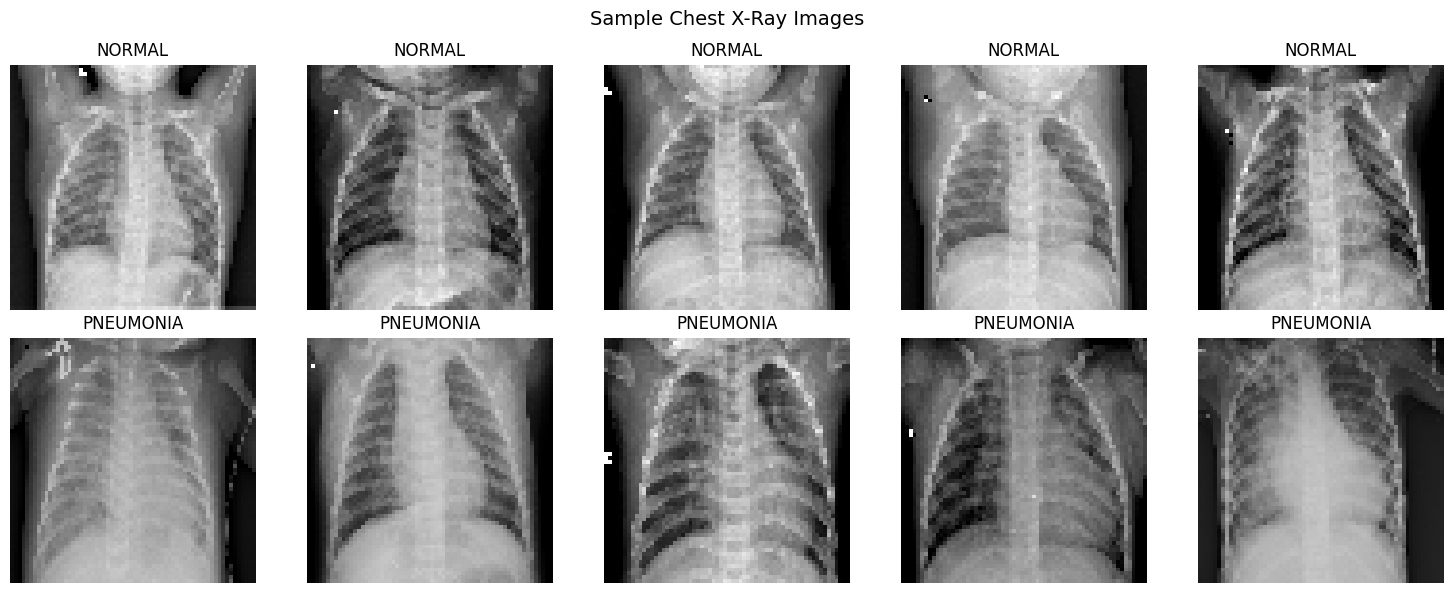

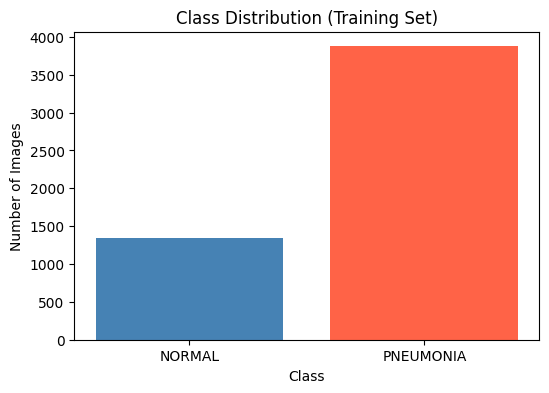

NORMAL images: 1341
PNEUMONIA images: 3875


In [ ]:
# Show sample images 
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle("Sample Chest X-Ray Images", fontsize=14)

classes = ['NORMAL', 'PNEUMONIA']
for row, cls in enumerate(classes):
    class_dir = os.path.join(train_dir, cls)
    images = os.listdir(class_dir)[:5]
    for col, img_name in enumerate(images):
        img_path = os.path.join(class_dir, img_name)
        img = load_img(img_path, target_size=IMG_SIZE)
        axes[row, col].imshow(img)
        axes[row, col].set_title(cls)
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()

# Show class distribution
train_counts = [len(os.listdir(os.path.join(train_dir, c))) for c in classes]
plt.figure(figsize=(6, 4))
plt.bar(classes, train_counts, color=['steelblue', 'tomato'])
plt.title("Class Distribution (Training Set)")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

print("NORMAL images:", train_counts[0])
print("PNEUMONIA images:", train_counts[1])

## Step 3 - Model Design aka brain of CNN architecture 
### Convolutional blocks
- Conv2d scans img looking for patterns
- MaxPooling2d shrinks img after each scan 
- Each block uses more filters (32 -> 64 -> 128)
### Flatten
- Squishes 3D block of scanned data into flat list
### Dense
- starts making sense of learned features
### Dropout
- Randomly turns off 50% of neurons during training to prevent model from memorizing training data
### Dense
- Final output layer. Closer to 0 = NORMAL, closer to 1 = PNEUMONIA

In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential([
    # First convolutional block
    Conv2D(32, (3, 3), activation='relu', input_shape=(64, 64, 3)),
    MaxPooling2D(2, 2),

    # Second convolutional block
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    # Third convolutional block
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    # Flatten and fully connected layers
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')  # Binary classification
])

model.summary()

C:\Users\garfi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,329 (2.61 MB)

 Trainable params: 683,329 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

## Step 4 - Model Training 
### Compiles the mode
- `optimizer='adam'` is how the model adjusts itself to get better
- `loss='binary_crossentropy'` measures how wrong model's predictions are. binary bc there's only 2 classes
- `metrics=['accuracy']` tells it to track accuracy to see how well it's doing 

### Training model `model.fit`
- `train_data` - the imgs it learns from 
- `epochs=10` - goes through training set 10 times
- `validation_data=val_data` checks itself against the val set to make sure it's learning and not memorizing

In [6]:
# Compile the model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_data,
    epochs=10,
    validation_data=val_data
)

Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 39s 226ms/step - accuracy: 0.8501 - loss: 0.3373 - val_accuracy: 0.7500 - val_loss: 0.5290
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 30s 186ms/step - accuracy: 0.9440 - loss: 0.1549 - val_accuracy: 0.7500 - val_loss: 0.6336
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 29s 174ms/step - accuracy: 0.9549 - loss: 0.1214 - val_accuracy: 0.6875 - val_loss: 0.6945
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 29s 179ms/step - accuracy: 0.9594 - loss: 0.1096 - val_accuracy: 0.9375 - val_loss: 0.2708
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 29s 180ms/step - accuracy: 0.9672 - loss: 0.0920 - val_accuracy: 1.0000 - val_loss: 0.1498
Epoch 6/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 30s 181ms/step - accuracy: 0.9722 - loss: 0.0711 - val_accuracy: 1.0000 - val_loss: 0.1743
Epoch 7/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 30s 181ms/step - accuracy: 0.9751 - loss: 0.0648 - val_accuracy: 0.8125 - val_loss: 0.2322
Epoch 8/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 30s 182ms/step - accuracy: 0.9774 - loss: 0

## Step 5 - Evaluation 

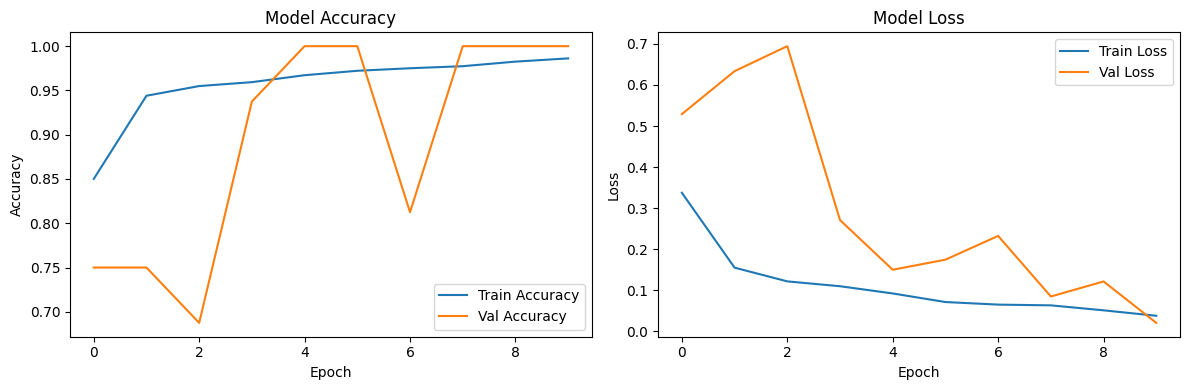

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 171ms/step - accuracy: 0.7949 - loss: 1.2765
Test Accuracy: 0.7949
Test Loss: 1.2765


In [ ]:
# Plot training history 
plt.figure(figsize=(12, 4))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# Evaluate on test set 
test_loss, test_accuracy = model.evaluate(test_data)
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

## Confusion Matrix

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 168ms/step


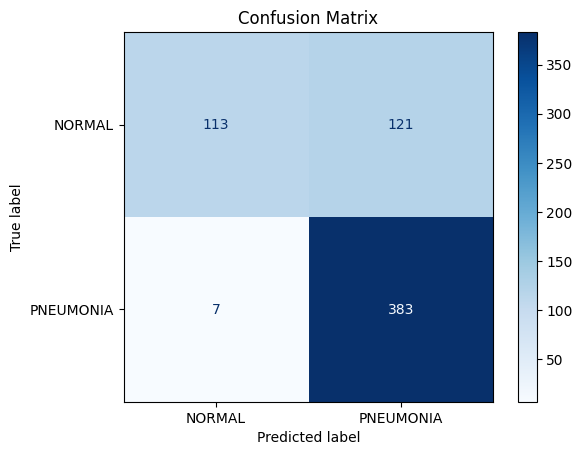

True Negatives (Correct NORMAL): 113
False Positives (NORMAL predicted as PNEUMONIA): 121
False Negatives (PNEUMONIA predicted as NORMAL): 7
True Positives (Correct PNEUMONIA): 383


In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

# Get true labels and predictions
test_data.reset()
y_pred = (model.predict(test_data) > 0.5).astype(int).flatten()
y_true = test_data.classes

# Plot confusion matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['NORMAL', 'PNEUMONIA'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# Print breakdown
print("True Negatives (Correct NORMAL):", cm[0][0])
print("False Positives (NORMAL predicted as PNEUMONIA):", cm[0][1])
print("False Negatives (PNEUMONIA predicted as NORMAL):", cm[1][0])
print("True Positives (Correct PNEUMONIA):", cm[1][1])

## Step 6 - Result Interpretation

### Model Performance
The CNN model achieved a test accuracy of 79.49%. While training accuracy reached 98.62%, 
the gap between training and test performance suggests overfitting -- the model got really 
good at the training data but didn't fully generalize to new images. The Dropout layer I 
included helped reduce this gap but didn't eliminate it entirely.

### Fixing an Evaluation Bug
My first confusion matrix didn't match my test accuracy. The correct predictions it 
showed added up to 62%, but model.evaluate reported 73%. The problem was that flow_from_directory
shuffles images by default, so the predictions came out in a shuffled order while the true
labels (test_data.classes) stayed in folder order. Every prediction was being compared to the
wrong image's label. I fixed it by setting shuffle=False on the test set only, since the 
training set should still be shuffled. Now the confusion matrix adds up to the same accuracy
as model.evaluate: (113 + 383) / 624 = 79.49%.

### Confusion Matrix Analysis
Looking at just the accuracy number doesn't tell the full story. The model correctly
identified 383 out of 390 pneumonia cases (98%) and only missed 7, which is really strong.
In medical screening, missing a sick patient is the worst mistake, so this matters most.
However it only correctly identified 113 out of 234 normal cases and flagged the other 121 as
pneumonia. The model is biased toward predicting pneumonia. My first guess was the class imbalance, 
since it saw almost 3 times as many pneumonia images during training (3,875 vs 1,341), so I tested that next.

### Improvement Attempt - Balancing the Data
To test whether the class imbalance was causing the bias, I undersampled the pneumonia class to 1,341 images
and trained a new model on the balanced set (see Step 7). The results were almost the same: 79.97% accuracy,
120 normal correct (vs 113), and 11 pneumonia missed (vs 7). Even with balanced classes, the model still flagged
about half the normal X-rays as pneumonia, so the imbalance wasn't the main problem. My best guess is the 64x64
image size losing detail. I kept the full dataset since it missed fewer pneumonia cases, which matters most in
medical screening.

### Strengths
- Very strong pneumonia detection: correctly identified 98% of pneumonia cases (383/390)
- Only 7 pneumonia cases missed
- Dropout layer helped reduce overfitting
- Simple architecture that trained in about 5 minutes on a CPU
- Tested undersampling and found the class imbalance wasn't the main cause of false positives
- Caught and fixed an evaluation bug by checking that my metrics agreed with each other

### Limitations
- Model struggled significantly with normal cases, only correctly identified 113 out of 234
- Small validation set (only 16 images) made val metrics unreliable and noisy
- Overfitting gap between training accuracy (98.62%) and test accuracy (79.49%)

### Potential Improvements
- Data augmentation on normal images to balance classes without losing data
- Increase image size from 64x64 to 128x128 to preserve more detail in X-rays
- Add early stopping so training halts when the model stops improving
- Use class weights instead of undersampling to handle imbalance

## Step 7 - Improvement Attempt: Undersampling

In [9]:
import pandas as pd

# Make a list of every training image and its label
rows = []
for cls in ['NORMAL', 'PNEUMONIA']:
    class_dir = os.path.join(train_dir, cls)
    for img_name in os.listdir(class_dir):
        rows.append({'filepath': os.path.join(class_dir, img_name), 'label': cls})
train_df = pd.DataFrame(rows)

# Keep all normal images, randomly pick 1,341 pneumonia images to match
normal_df = train_df[train_df['label'] == 'NORMAL']
pneumonia_df = train_df[train_df['label'] == 'PNEUMONIA'].sample(n=len(normal_df), random_state=42)
balanced_df = pd.concat([normal_df, pneumonia_df])

print(balanced_df['label'].value_counts())

label
NORMAL       1341
PNEUMONIA    1341
Name: count, dtype: int64


In [10]:
balanced_data = train_datagen.flow_from_dataframe(
    balanced_df,
    x_col='filepath',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=['NORMAL', 'PNEUMONIA']
)

Found 2682 validated image filenames belonging to 2 classes.


In [11]:
model_us = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(64, 64, 3)),
    MaxPooling2D(2, 2),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model_us.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history_us = model_us.fit(balanced_data, epochs=10, validation_data=val_data)

C:\Users\garfi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 26s 288ms/step - accuracy: 0.7644 - loss: 0.4516 - val_accuracy: 0.6250 - val_loss: 0.8042
Epoch 2/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 19s 231ms/step - accuracy: 0.9265 - loss: 0.1880 - val_accuracy: 0.8750 - val_loss: 0.2173
Epoch 3/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 20s 238ms/step - accuracy: 0.9448 - loss: 0.1419 - val_accuracy: 0.8750 - val_loss: 0.2521
Epoch 4/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 19s 229ms/step - accuracy: 0.9567 - loss: 0.1224 - val_accuracy: 0.9375 - val_loss: 0.1817
Epoch 5/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 20s 236ms/step - accuracy: 0.9605 - loss: 0.1102 - val_accuracy: 0.8750 - val_loss: 0.2865
Epoch 6/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 20s 235ms/step - accuracy: 0.9642 - loss: 0.0955 - val_accuracy: 1.0000 - val_loss: 0.1336
Epoch 7/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 20s 238ms/step - accuracy: 0.9646 - loss: 0.0941 - val_accuracy: 1.0000 - val_loss: 0.0616
Epoch 8/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 20s 239ms/step - accuracy: 0.9765 - loss: 0.0758 - val_accu

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 183ms/step - accuracy: 0.7997 - loss: 0.6090
Undersampled Test Accuracy: 0.7997
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 144ms/step


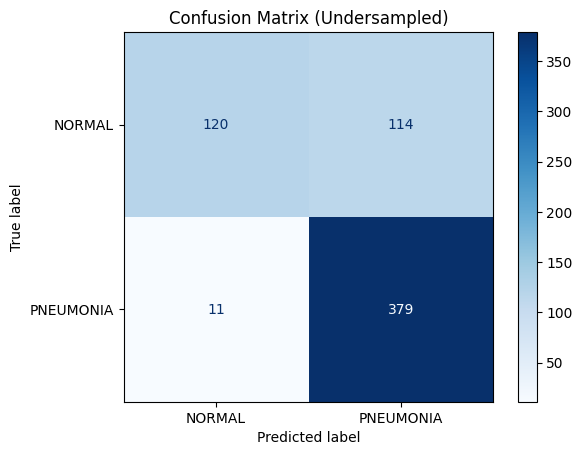

Correct NORMAL: 120
False Positives: 114
False Negatives: 11
Correct PNEUMONIA: 379


In [12]:
test_loss_us, test_acc_us = model_us.evaluate(test_data)
print(f"Undersampled Test Accuracy: {test_acc_us:.4f}")

test_data.reset()
y_pred_us = (model_us.predict(test_data) > 0.5).astype(int).flatten()
cm_us = confusion_matrix(y_true, y_pred_us)

ConfusionMatrixDisplay(confusion_matrix=cm_us, display_labels=['NORMAL', 'PNEUMONIA']).plot(cmap='Blues')
plt.title("Confusion Matrix (Undersampled)")
plt.show()

print("Correct NORMAL:", cm_us[0][0])
print("False Positives:", cm_us[0][1])
print("False Negatives:", cm_us[1][0])
print("Correct PNEUMONIA:", cm_us[1][1])